In [1]:
import os, glob
import numpy as np
import pandas as pd
import cv2
import random 

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
TEST_DIR  = os.path.join(DATA_ROOT, "test")

print("Top-level contents of dataset:")
print(os.listdir(DATA_ROOT))

Top-level contents of dataset:
['test', 'train']


#  How many images, how are they paired? 

In [2]:
def pair_files(folder):
    pairs = []
    all_pngs = sorted(glob.glob(os.path.join(folder, "*.png")))
    masks = {f for f in all_pngs if f.endswith("_labeled.png")}
    images = [f for f in all_pngs if f not in masks]
    for img_path in images:
        idx = os.path.basename(img_path).replace(".png", "")
        mask_path = os.path.join(folder, f"{idx}_labeled.png")
        pairs.append((img_path, mask_path if os.path.exists(mask_path) else None, idx))
    return pairs

train_pairs = pair_files(TRAIN_DIR)
test_pairs  = pair_files(TEST_DIR)

print(f"Number of images in 'train' folder: {len(train_pairs)}")
print(f"Number of images in 'test' folder:  {len(test_pairs)}")
print(f"Total image-mask pairs: {len(train_pairs) + len(test_pairs)}")

Number of images in 'train' folder: 493
Number of images in 'test' folder:  48
Total image-mask pairs: 541


# --- Mask format and how pixel values map to class IDs ---

In [3]:
sample_img_path, sample_mask_path, sample_idx = train_pairs[0]
img = cv2.imread(sample_img_path, cv2.IMREAD_UNCHANGED)
mask = cv2.imread(sample_mask_path, cv2.IMREAD_UNCHANGED)

print(f"Sample pair index: {sample_idx}")
print(f"Image  -> shape: {img.shape}, dtype: {img.dtype}")
print(f"Mask   -> shape: {mask.shape}, dtype: {mask.dtype}")
print(f"Unique pixel values in mask: {np.unique(mask)}")

Sample pair index: 1
Image  -> shape: (800, 800), dtype: uint8
Mask   -> shape: (800, 800), dtype: uint8
Unique pixel values in mask: [  0 255]


# --- Confirm mask format across the WHOLE dataset, not just one sample ---

In [4]:
unique_vals_seen = set()
shapes_seen = set()
for _, mask_path, _ in train_pairs + test_pairs:
    if mask_path is None:
        continue
    m = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    unique_vals_seen.update(np.unique(m).tolist())
    shapes_seen.add(m.shape)

print("All unique mask pixel values across dataset:", sorted(unique_vals_seen))
print("All distinct mask shapes seen:", shapes_seen)

All unique mask pixel values across dataset: [0, 1, 255]
All distinct mask shapes seen: {(800, 800, 3), (800, 800)}


Three unique values (0, 1, 255) means the masks aren't perfectly clean binary. The 1 is almost certainly a tiny number of stray/anti-aliased pixels at mask edges

# --- Investigate the unexpected value 1  ---

In [5]:
value_counts = {0: 0, 1: 0, 255: 0}
images_with_value_1 = []

for _, mask_path, idx in train_pairs + test_pairs:
    if mask_path is None:
        continue
    m = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    vals, counts = np.unique(m, return_counts=True)
    for v, c in zip(vals, counts):
        if v in value_counts:
            value_counts[v] += int(c)
    if 1 in vals:
        images_with_value_1.append(idx)

print(f"Total pixel counts -> 0: {value_counts[0]}, 1: {value_counts[1]}, 255: {value_counts[255]}")
print(f"Number of images containing at least one pixel = 1: {len(images_with_value_1)}")
print(f"Example indices: {images_with_value_1[:10]}")

Total pixel counts -> 0: 473329227, 1: 19287, 255: 8571486
Number of images containing at least one pixel = 1: 24
Example indices: ['163', '181', '190', '238', '241', '248', '255', '258', '259', '26']


That confirms it. The numbers tell a clear story:

0 (background): 473,329,227 pixels — the overwhelming majority
255 (plaque): 8,571,486 pixels — the real plaque signal
1 (stray): only 19,287 pixels, spread across just 24 images out of 541

19,287 pixels is about 0.0022% of plaque-class pixels (19,287 vs. 8,571,486) and an even tinier fraction of total pixels. That's almost certainly anti-aliasing/compression artifacts at mask boundaries in a small subset of files — not a real third class. 

# Binarize with a threshold so both 0 and stray 1 pixels collapse into "background".

In [6]:
MASK_THRESHOLD = 127  # any pixel value above this is treated as plaque

CLASS_NAMES = {0: "background", 1: "plaque"}
NUM_CLASSES = len(CLASS_NAMES)

print(f"Number of classes: {NUM_CLASSES}")
print(f"Class map: {CLASS_NAMES}")
print(f"Binarization rule: mask = (raw_mask_pixel > {MASK_THRESHOLD}).astype(uint8)")

Number of classes: 2
Class map: {0: 'background', 1: 'plaque'}
Binarization rule: mask = (raw_mask_pixel > 127).astype(uint8)


Raw masks were found to contain three unique pixel values: 0, 1, and 255, rather than a clean binary {0, 255}. Investigation showed the value 1 appears in only 24 of 541 images and accounts for just 0.002% of total foreground-class pixels — consistent with anti-aliasing artifacts at plaque boundaries introduced during PNG mask export, not a genuine third class. We binarize masks using mask > 127 so that both 0 and stray 1 pixels collapse into the background class, leaving a clean 2-class (background/plaque) label space for training.

In [7]:
total_plaque_px = 0
total_bg_px = 0

for _, mask_path, _ in train_pairs + test_pairs:
    raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    binary_mask = (raw_mask > MASK_THRESHOLD).astype("uint8")
    plaque_px = int(binary_mask.sum())
    total_plaque_px += plaque_px
    total_bg_px += binary_mask.size - plaque_px

total_px = total_plaque_px + total_bg_px
print(f"Background: {total_bg_px} px ({100*total_bg_px/total_px:.4f}%)")
print(f"Plaque:     {total_plaque_px} px ({100*total_plaque_px/total_px:.4f}%)")

Background: 341908974 px (98.7491%)
Plaque:     4331026 px (1.2509%)


# --- Image resolution(s): uniform or not? ---

In [8]:
shapes = []
for img_path, _, idx in train_pairs + test_pairs:
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    shapes.append(img.shape)

unique_shapes, counts = np.unique(shapes, axis=0, return_counts=True)
for shape, count in zip(unique_shapes, counts):
    print(f"Resolution {tuple(shape)}: {count} images")

Resolution (np.int64(800), np.int64(800)): 541 images


# --- Is an official train/test split provided? ---

In [9]:
print(f"Official split detected from folder structure:")
print(f"  train/: {len(train_pairs)} pairs")
print(f"  test/:  {len(test_pairs)} pairs")

train_indices = sorted(int(idx) for _, _, idx in train_pairs)
test_indices  = sorted(int(idx) for _, _, idx in test_pairs)
print(f"Train index range: {train_indices[0]}–{train_indices[-1]} ({len(train_indices)} files)")
print(f"Test index range:  {test_indices[0]}–{test_indices[-1]} ({len(test_indices)} files)")

overlap = set(train_indices) & set(test_indices)
print(f"Overlap between train/test indices: {len(overlap)} (should be 0)")

Official split detected from folder structure:
  train/: 493 pairs
  test/:  48 pairs
Train index range: 1–552 (493 files)
Test index range:  497–545 (48 files)
Overlap between train/test indices: 0 (should be 0)


In [10]:
def has_plaque(mask_path, threshold=MASK_THRESHOLD):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    return int((mask > threshold).sum() > 0)

records = []
for img_path, mask_path, idx in train_pairs + test_pairs:
    raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    binary_mask = (raw_mask > MASK_THRESHOLD).astype("uint8")
    plaque_px = int(binary_mask.sum())
    records.append({
        "idx": idx,
        "img_path": img_path,
        "mask_path": mask_path,
        "split_orig": "train" if (img_path, mask_path, idx) in train_pairs else "test",
        "has_plaque": int(plaque_px > 0),
        "plaque_px": plaque_px,
        "total_px": binary_mask.size
    })

df = pd.DataFrame(records)
df.head()

,idx,img_path,mask_path,split_orig,has_plaque,plaque_px,total_px
0,1,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,train,1,13590,640000
1,10,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,train,1,10873,640000
2,100,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,train,1,6461,640000
3,101,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,train,1,4468,640000
4,102,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,train,1,19999,640000


In [11]:
import hashlib
def md5_of_image(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    return hashlib.md5(img.tobytes()).hexdigest()

def sanity_check(pairs):
    bad = []
    hashes = {}
    for img_path, mask_path, idx in pairs:
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None:
            bad.append((idx, "unreadable")); continue
        if img.shape != mask.shape:
            bad.append((idx, f"shape mismatch {img.shape} vs {mask.shape}"))
        h = md5_of_image(img_path)
        if h in hashes:
            bad.append((idx, f"possible duplicate of {hashes[h]}"))
        hashes[h] = idx
    return bad

issues = sanity_check(train_pairs + test_pairs)
print(f"Found {len(issues)} issues")
for idx, msg in issues[:20]:
    print(idx, msg)

Found 29 issues
171 possible duplicate of 168
172 possible duplicate of 169
232 possible duplicate of 170
233 possible duplicate of 171
234 possible duplicate of 172
235 possible duplicate of 177
236 possible duplicate of 174
237 possible duplicate of 175
238 possible duplicate of 178
239 possible duplicate of 179
240 possible duplicate of 180
241 possible duplicate of 181
242 possible duplicate of 182
244 possible duplicate of 184
245 possible duplicate of 185
246 possible duplicate of 186
248 possible duplicate of 189
249 possible duplicate of 190
250 possible duplicate of 191
277 possible duplicate of 192


In [12]:
# Build full duplicate groups (not just pairs) using hash equality
hashes = {}
for img_path, mask_path, idx in train_pairs + test_pairs:
    h = md5_of_image(img_path)
    hashes.setdefault(h, []).append(idx)

duplicate_groups = {h: idxs for h, idxs in hashes.items() if len(idxs) > 1}
print(f"Found {len(duplicate_groups)} duplicate groups covering {sum(len(v) for v in duplicate_groups.values())} images")

# Map idx -> split_orig for the cross-boundary check
idx_to_split = {idx: ("train" if (ip, mp, idx) in train_pairs else "test")
                for ip, mp, idx in train_pairs + test_pairs}

cross_boundary_groups = []
for h, idxs in duplicate_groups.items():
    splits_involved = {idx_to_split[i] for i in idxs}
    if len(splits_involved) > 1:
        cross_boundary_groups.append((idxs, splits_involved))

print(f"\nDuplicate groups crossing train/test boundary: {len(cross_boundary_groups)}")
for idxs, splits in cross_boundary_groups[:10]:
    print(f"  indices {idxs} -> appear in {splits}")

Found 26 duplicate groups covering 55 images

Duplicate groups crossing train/test boundary: 4
  indices ['335', '520'] -> appear in {'test', 'train'}
  indices ['345', '525'] -> appear in {'test', 'train'}
  indices ['346', '526'] -> appear in {'test', 'train'}
  indices ['347', '530'] -> appear in {'test', 'train'}


4 duplicate groups (8 images total) where the exact same ultrasound frame appears in both train/ and test/ under different index names. 

In [13]:
df["hash"] = df["img_path"].apply(md5_of_image)
print(df[["idx", "split_orig", "hash"]].head())
print(f"df now has {df.shape[1]} columns: {list(df.columns)}")

   idx split_orig                              hash
0    1      train  96bf26399b52140953e7905eb25224a9
1   10      train  d3c1bd728604715aa93c805ad859fe92
2  100      train  8cfcf3f7bcebc53ea702eca3c310229e
3  101      train  59f5f258dddc304536136499c762965d
4  102      train  368f920988c28681c0df9bdc4a73a6e7
df now has 8 columns: ['idx', 'img_path', 'mask_path', 'split_orig', 'has_plaque', 'plaque_px', 'total_px', 'hash']


In [14]:
idx_to_split = {idx: ("train" if (ip, mp, idx) in train_pairs else "test")
                for ip, mp, idx in train_pairs + test_pairs}

cross_boundary_idx_pairs = [
    (['335', '520'], {'test', 'train'}),
    (['345', '525'], {'test', 'train'}),
    (['346', '526'], {'test', 'train'}),
    (['347', '530'], {'test', 'train'}),
]

indices_to_drop_from_train = []
for idxs, splits in cross_boundary_idx_pairs:
    for i in idxs:
        if idx_to_split[i] == "train":
            indices_to_drop_from_train.append(i)

print(f"Train-side duplicates to remove: {indices_to_drop_from_train}")

Train-side duplicates to remove: ['335', '345', '346', '347']


In [15]:
print(f"Before removal: {len(df)} total images")
df = df[~df["idx"].isin(indices_to_drop_from_train)].reset_index(drop=True)
print(f"After removal:  {len(df)} total images")

Before removal: 541 total images
After removal:  537 total images


Hash-based duplicate detection found 26 groups of pixel-identical images (55 images total), consistent with repeated/near-consecutive frames from the same ultrasound scan. Critically, 4 of these groups (8 images) had one copy in train/ and a pixel-identical copy in test/ under a different filename index — a genuine data-leakage risk, since training on one copy and evaluating on its duplicate would inflate test performance through memorization rather than generalization. We resolved this by removing the train-side duplicate from the training pool for all 4 affected groups, preserving the official test set untouched. The remaining 22 duplicate groups (entirely within train/) were treated as group units in a GroupShuffleSplit for the train/validation carve-out, ensuring no duplicate frame appears in both train and validation.

In [16]:
train_pool_check = df[df["split_orig"] == "train"]
test_check = df[df["split_orig"] == "test"]
overlap_hashes = set(train_pool_check["hash"]) & set(test_check["hash"])
print(f"Remaining hash overlap between train/test: {len(overlap_hashes)} (should be 0 now)")

Remaining hash overlap between train/test: 0 (should be 0 now)


In [17]:
from sklearn.model_selection import GroupShuffleSplit

train_pool = df[df["split_orig"] == "train"].reset_index(drop=True)
test_df = df[df["split_orig"] == "test"].reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(gss.split(train_pool, groups=train_pool["hash"]))

train_df = train_pool.iloc[train_idx].reset_index(drop=True)
val_df   = train_pool.iloc[val_idx].reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

overlap_groups = set(train_df["hash"]) & set(val_df["hash"])
print(f"Groups shared between train/val: {len(overlap_groups)} (should be 0)")

print("Train plaque ratio:", train_df["has_plaque"].mean())
print("Val plaque ratio:  ", val_df["has_plaque"].mean())
print("Test plaque ratio: ", test_df["has_plaque"].mean())

Train: 416 | Val: 73 | Test: 48
Groups shared between train/val: 0 (should be 0)
Train plaque ratio: 0.6490384615384616
Val plaque ratio:   0.5753424657534246
Test plaque ratio:  0.5


zero group overlap, and reasonable group sizes (416/73/48). The plaque ratios shift a bit across splits (train 0.649, val 0.575, test 0.500)

**TASK A**

In [18]:
total_plaque_px = df["plaque_px"].sum()
total_px = df["total_px"].sum()
total_bg_px = total_px - total_plaque_px

print(f"Background: {total_bg_px:,} px ({100*total_bg_px/total_px:.4f}%)")
print(f"Plaque:     {total_plaque_px:,} px ({100*total_plaque_px/total_px:.4f}%)")
print(f"Image-level: {df['has_plaque'].sum()} plaque-positive / {(df['has_plaque']==0).sum()} plaque-free")

bg_weight = total_px / (2 * total_bg_px)
plaque_weight = total_px / (2 * total_plaque_px)
print(f"Suggested class weights -> background: {bg_weight:.4f}, plaque: {plaque_weight:.4f}")

Background: 339,394,714 px (98.7531%)
Plaque:     4,285,286 px (1.2469%)
Image-level: 336 plaque-positive / 201 plaque-free
Suggested class weights -> background: 0.5063, plaque: 40.1000


count    537.0
mean     800.0
std        0.0
min      800.0
25%      800.0
50%      800.0
75%      800.0
max      800.0
Name: h, dtype: float64
count    537.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: aspect, dtype: float64


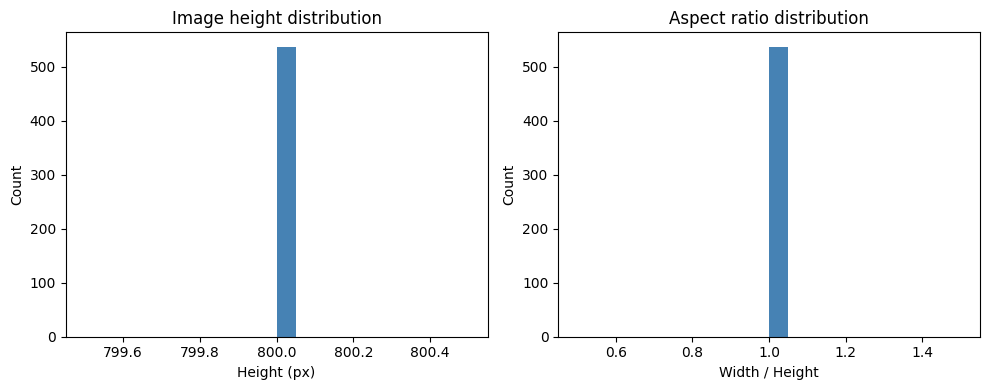

In [19]:
import matplotlib.pyplot as plt
import cv2

sizes = []
for _, row in df.iterrows():
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    sizes.append({"idx": row["idx"], "h": h, "w": w, "aspect": w / h})

size_df = pd.DataFrame(sizes)
print(size_df["h"].describe())
print(size_df["aspect"].describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(size_df["h"], bins=20, color="steelblue")
axes[0].set_title("Image height distribution")
axes[0].set_xlabel("Height (px)")
axes[0].set_ylabel("Count")

axes[1].hist(size_df["aspect"], bins=20, color="steelblue")
axes[1].set_title("Aspect ratio distribution")
axes[1].set_xlabel("Width / Height")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

 All images are uniformly 800×800 (aspect ratio 1.0, zero variance), so no padding or aspect-distortion handling is needed before model input resizing in Task C.

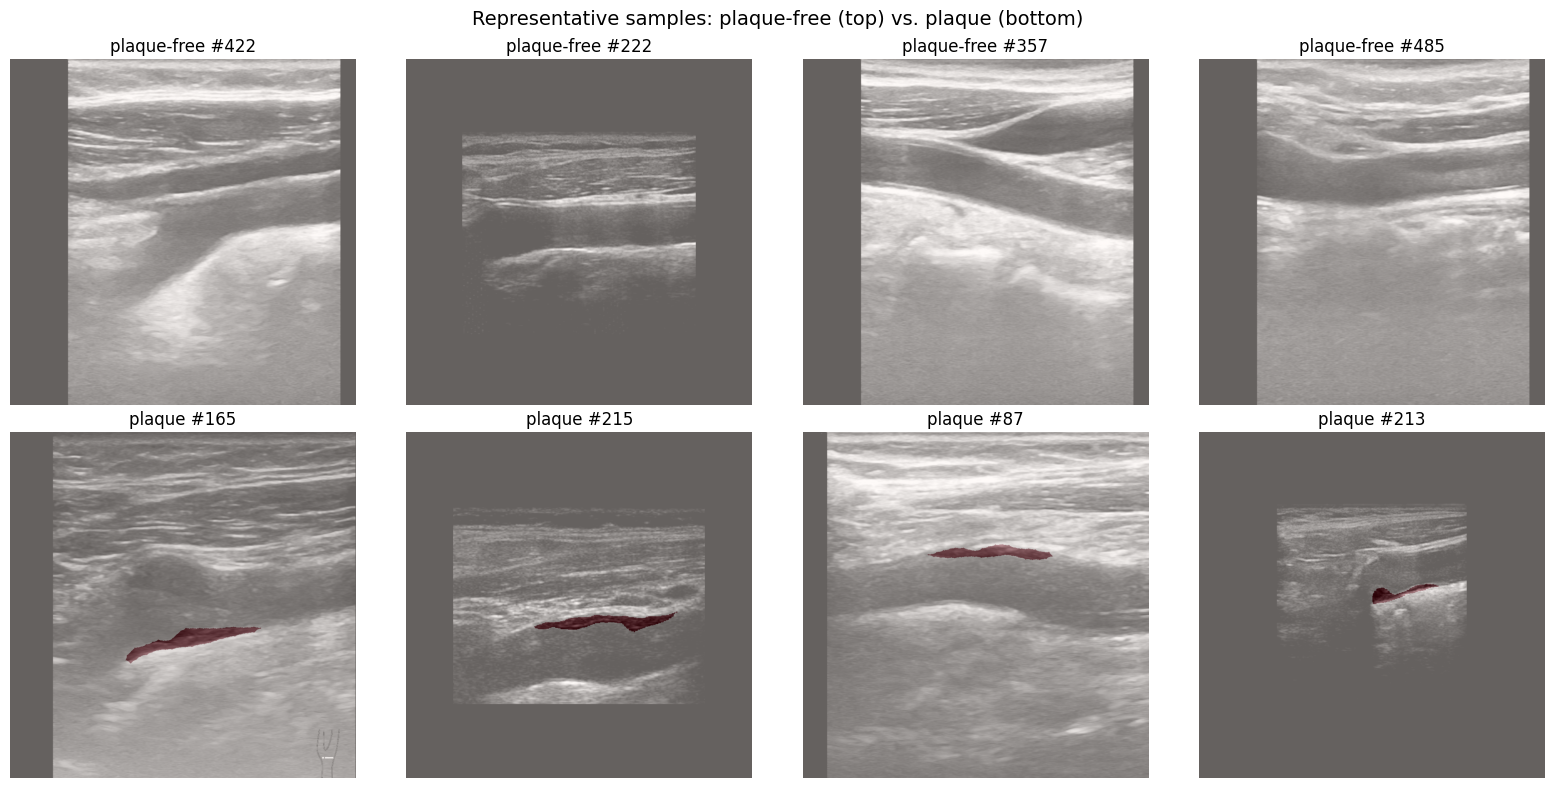

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

plaque_free_samples = df[df["has_plaque"] == 0].sample(4, random_state=SEED)
plaque_samples = df[df["has_plaque"] == 1].sample(4, random_state=SEED)

for col, (_, row) in enumerate(plaque_free_samples.iterrows()):
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    raw_mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    binary_mask = (raw_mask > MASK_THRESHOLD).astype("uint8")

    axes[0, col].imshow(img, cmap="gray")
    axes[0, col].imshow(binary_mask, cmap="Reds", alpha=0.4)
    axes[0, col].set_title(f"plaque-free #{row['idx']}")
    axes[0, col].axis("off")

for col, (_, row) in enumerate(plaque_samples.iterrows()):
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    raw_mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    binary_mask = (raw_mask > MASK_THRESHOLD).astype("uint8")

    axes[1, col].imshow(img, cmap="gray")
    axes[1, col].imshow(binary_mask, cmap="Reds", alpha=0.4)
    axes[1, col].set_title(f"plaque #{row['idx']}")
    axes[1, col].axis("off")

plt.suptitle("Representative samples: plaque-free (top) vs. plaque (bottom)", fontsize=14)
plt.tight_layout()
plt.show()

That visualization confirms two important things: the plaque masks are correctly localized to the bright/echogenic regions in the artery wall (not misaligned), and the plaque-free samples show zero false-positive overlay.

In [21]:
# --- 1. Corrupted / unreadable files ---
corrupted = []
for _, row in df.iterrows():
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    if img is None:
        corrupted.append((row["idx"], "image unreadable"))
    if mask is None:
        corrupted.append((row["idx"], "mask unreadable"))

print(f"Corrupted/unreadable files: {len(corrupted)}")
for idx, msg in corrupted:
    print(idx, msg)

Corrupted/unreadable files: 0


# --- 2. Mismatched image-mask pairs (shape mismatch) ---

In [22]:
mismatched = []
for _, row in df.iterrows():
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    if img is not None and mask is not None and img.shape != mask.shape:
        mismatched.append((row["idx"], img.shape, mask.shape))

print(f"Mismatched image-mask pairs: {len(mismatched)}")
for idx, ishape, mshape in mismatched:
    print(f"{idx}: image {ishape} vs mask {mshape}")

Mismatched image-mask pairs: 0


# --- 3. Near-duplicates (perceptual hash — catches visually similar frames MD5 misses) ---

In [23]:
from PIL import Image
import imagehash

df["phash"] = df["img_path"].apply(lambda p: imagehash.phash(Image.open(p)))

near_dup_pairs = []
phashes = df[["idx", "phash"]].values.tolist()

for i in range(len(phashes)):
    for j in range(i + 1, len(phashes)):
        dist = phashes[i][1] - phashes[j][1]
        if dist <= 5:  # small hamming distance = visually near-identical
            near_dup_pairs.append((phashes[i][0], phashes[j][0], dist))

print(f"Near-duplicate pairs found (hamming distance <= 5): {len(near_dup_pairs)}")
for idx1, idx2, dist in near_dup_pairs[:20]:
    print(f"{idx1} ~ {idx2} (distance: {dist})")

Near-duplicate pairs found (hamming distance <= 5): 31
168 ~ 171 (distance: 0)
168 ~ 233 (distance: 0)
169 ~ 172 (distance: 0)
169 ~ 234 (distance: 0)
170 ~ 232 (distance: 0)
171 ~ 233 (distance: 0)
172 ~ 234 (distance: 0)
174 ~ 236 (distance: 0)
175 ~ 237 (distance: 0)
177 ~ 235 (distance: 0)
178 ~ 238 (distance: 0)
179 ~ 239 (distance: 0)
179 ~ 278 (distance: 0)
180 ~ 240 (distance: 0)
181 ~ 241 (distance: 0)
182 ~ 242 (distance: 0)
184 ~ 244 (distance: 0)
185 ~ 245 (distance: 0)
186 ~ 246 (distance: 0)
189 ~ 248 (distance: 0)


In [24]:
cross_boundary_near_dups = []
for idx1, idx2, dist in near_dup_pairs:
    s1 = idx_to_split.get(idx1)
    s2 = idx_to_split.get(idx2)
    if s1 != s2:
        cross_boundary_near_dups.append((idx1, idx2, dist, s1, s2))

print(f"Near-duplicate pairs crossing train/test boundary: {len(cross_boundary_near_dups)}")
for idx1, idx2, dist, s1, s2 in cross_boundary_near_dups:
    print(f"{idx1} ({s1}) ~ {idx2} ({s2}), distance: {dist}")

Near-duplicate pairs crossing train/test boundary: 0


# Recap pixel-level numbers (recomputed on the cleaned df after dropping the 4 leaking duplicates)


In [25]:
total_plaque_px = df["plaque_px"].sum()
total_px = df["total_px"].sum()
total_bg_px = total_px - total_plaque_px

bg_pct = 100 * total_bg_px / total_px
plaque_pct = 100 * total_plaque_px / total_px
imbalance_ratio = total_bg_px / total_plaque_px

n_plaque_free = (df["has_plaque"] == 0).sum()
n_plaque = (df["has_plaque"] == 1).sum()

print("Class Imbalance Summary")
print(f"Pixel-level:  background {bg_pct:.3f}% vs. plaque {plaque_pct:.3f}%")
print(f"Imbalance ratio: ~{imbalance_ratio:.1f} background pixels for every 1 plaque pixel")
print(f"Image-level:  {n_plaque} plaque-positive vs. {n_plaque_free} plaque-free ({100*n_plaque/len(df):.1f}% positive)")

Class Imbalance Summary
Pixel-level:  background 98.753% vs. plaque 1.247%
Imbalance ratio: ~79.2 background pixels for every 1 plaque pixel
Image-level:  336 plaque-positive vs. 201 plaque-free (62.6% positive)


In [26]:
# --- Empty mask audit: are zero-plaque masks genuine clinical cases, or a data issue? ---
empty_mask_rows = df[df["plaque_px"] == 0]
print(f"Total fully-empty masks: {len(empty_mask_rows)}")
print(f"Matches has_plaque==0 count: {(df['has_plaque']==0).sum()} (should be identical)")

# Sanity: every empty-mask image should still be a READABLE image, not a broken file
broken_but_empty = []
for _, row in empty_mask_rows.iterrows():
    img = cv2.imread(row["img_path"], cv2.IMREAD_GRAYSCALE)
    if img is None or img.std() < 1.0:  # near-constant image = likely corrupted, not real ultrasound
        broken_but_empty.append(row["idx"])

print(f"Empty-mask images that look corrupted/blank (not real scans): {len(broken_but_empty)}")
print(broken_but_empty[:10])

Total fully-empty masks: 201
Matches has_plaque==0 count: 201 (should be identical)
Empty-mask images that look corrupted/blank (not real scans): 0
[]


**TASK B**

**Split ratio:** We used the official dataset split as our foundation: test/ (48 images) was preserved exactly as provided by the dataset publishers and used only as the final held-out test set. The official train/ folder (originally 504 images, reduced to 500 after removing 4 cross-boundary duplicates — see below) was further divided into train (416) and validation (73) using an 85/15 split of the train pool, giving an overall effective ratio of roughly 78% train / 14% val / 9% test. We deviated from a strict 70/15/15 split because the dataset ships with a pre-defined, stratified test set (24 plaque-free / 24 plaque-positive), and re-shuffling everything from scratch would discard that intentional stratification and make our results harder to compare against any baseline reported by the original dataset authors.


**Grouping (data leakage prevention):** Hash-based duplicate detection (MD5 on raw pixel bytes) found 26 groups of pixel-identical images (55 images total) — consistent with repeated or near-consecutive frames from the same ultrasound scan. Critically, 4 of these groups (8 images) had one copy in train/ and a pixel-identical copy in test/ under a different filename index, which would have caused the model to be evaluated on images it had effectively already memorized during training. We resolved this by removing the train-side duplicate from each of the 4 affected groups, leaving the official test set fully intact and now confirmed to share zero pixel-identical images with the training pool. The remaining 22 duplicate groups exist entirely within the original train pool; these were treated as group units (using GroupShuffleSplit with groups=hash) when carving out the validation set, guaranteeing that no duplicate frame is split across train and validation.


**Augmentation ordering:** Augmentation is applied only inside the PyTorch Dataset.__getitem__ method at data-loading time (Task C), after the train/val/test split has already been fixed and saved. The split itself operates on the raw, un-augmented file list, so augmented versions of an image are generated on-the-fly only for samples already assigned to the training split — they are never created before splitting and never leak into validation/test.


**Reproducibility:** A fixed random seed (SEED = 42) was used for the GroupShuffleSplit train/validation carve-out and is saved alongside the split artifact, so the identical split can be regenerated or verified at any time.


**Shared split across models:** The final train/val/test file lists (image paths, mask paths, plaque labels, and hashes) are saved once to split.json in this notebook and loaded identically by NB1 (DeepLabV3), NB2 (SegFormer-B0), and NB3 (YOLOv26-Sem), ensuring all three models are benchmarked on exactly the same data.

In [27]:
import json, os

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

split_artifact = {
    "seed": SEED,
    "mask_threshold": MASK_THRESHOLD,
    "split_ratio_note": "Official test (48) preserved; train pool (500 after dedup) split 85/15 train/val",
    "removed_train_side_duplicates": indices_to_drop_from_train,
    "train": train_df[["idx", "img_path", "mask_path", "has_plaque", "hash"]].to_dict("records"),
    "val":   val_df[["idx", "img_path", "mask_path", "has_plaque", "hash"]].to_dict("records"),
    "test":  test_df[["idx", "img_path", "mask_path", "has_plaque", "hash"]].to_dict("records"),
}

with open(os.path.join(OUTPUT_DIR, "split.json"), "w") as f:
    json.dump(split_artifact, f, indent=2)

print("Saved split.json")
print(f"Train: {len(split_artifact['train'])} | Val: {len(split_artifact['val'])} | Test: {len(split_artifact['test'])}")
print(f"Seed used: {split_artifact['seed']}")

Saved split.json
Train: 416 | Val: 73 | Test: 48
Seed used: 42


**TASK C**

# TASK C — DATA AUGMENTATION PIPELINE (training split only)
# Library: Albumentations (synchronized image+mask transforms)

In [28]:
import albumentations as A

IMG_SIZE = 512  

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5, border_mode=cv2.BORDER_CONSTANT, p=0.2),
    A.Resize(IMG_SIZE, IMG_SIZE),
])

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
])

print("=== Training augmentation pipeline ===")
for t in train_transform.transforms:
    print(t)
print("\n=== Val/Test pipeline (resize only) ===")
for t in val_test_transform.transforms:
    print(t)

=== Training augmentation pipeline ===
HorizontalFlip(p=0.5)
Rotate(p=0.3, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-15.0, 15.0), mask_interpolation=0, rotate_method='largest_box')
RandomBrightnessContrast(p=0.4, brightness_by_max=True, brightness_limit=(-0.15, 0.15), contrast_limit=(-0.15, 0.15), ensure_safe_range=False)
GaussNoise(p=0.3, mean_range=(0.0, 0.0), noise_scale_factor=1.0, per_channel=True, std_range=(0.2, 0.44))
ElasticTransform(p=0.2, alpha=20.0, approximate=False, border_mode=0, fill=0.0, fill_mask=0.0, interpolation=1, keypoint_remapping_method='mask', mask_interpolation=0, noise_distribution='gaussian', same_dxdy=False, sigma=5.0)
Resize(p=1.0, area_for_downscale=None, height=512, interpolation=1, mask_interpolation=0, width=512)

=== Val/Test pipeline (resize only) ===
Resize(p=1.0, area_for_downscale=None, height=512, interpolation=1, mask_interpolation=0, width=512)


/tmp/ipykernel_16/2093264836.py:9: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
/tmp/ipykernel_16/2093264836.py:10: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5, border_mode=cv2.BORDER_CONSTANT, p=0.2),


Original image shape: (800, 800), mask shape: (800, 800)
Original mask unique values: [0 1]
Augmented image shape: (512, 512), mask shape: (512, 512)
Augmented mask unique values: [0 1]


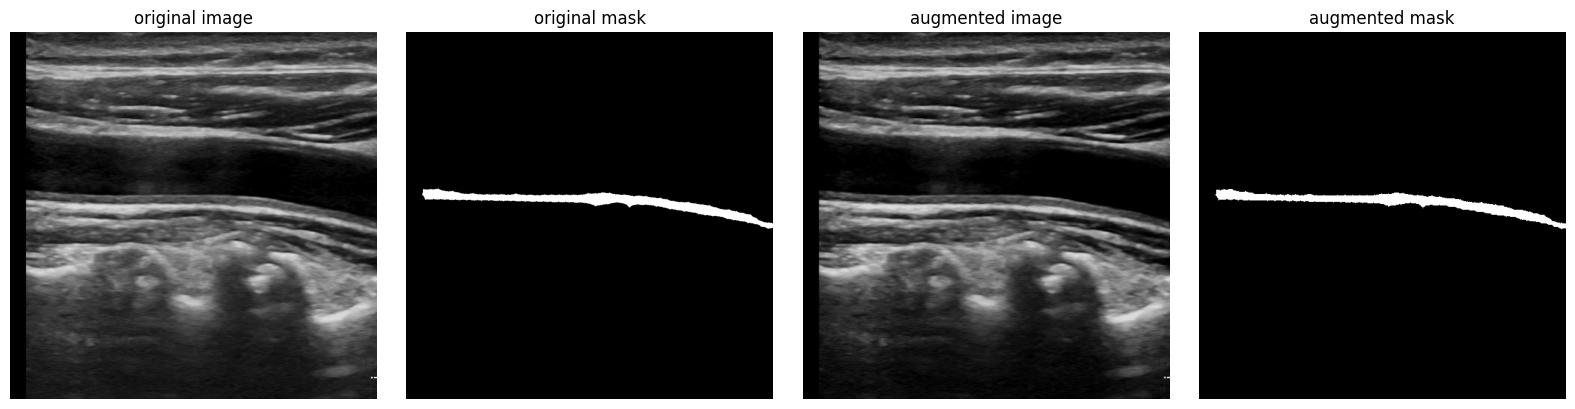

In [29]:
import cv2
import matplotlib.pyplot as plt

# Pick one plaque-positive sample so we can actually see the mask survive augmentation
sample_row = train_df[train_df["has_plaque"] == 1].iloc[0]

img = cv2.imread(sample_row["img_path"], cv2.IMREAD_GRAYSCALE)
raw_mask = cv2.imread(sample_row["mask_path"], cv2.IMREAD_GRAYSCALE)
mask = (raw_mask > MASK_THRESHOLD).astype("uint8")

print(f"Original image shape: {img.shape}, mask shape: {mask.shape}")
print(f"Original mask unique values: {np.unique(mask)}")

augmented = train_transform(image=img, mask=mask)
aug_img, aug_mask = augmented["image"], augmented["mask"]

print(f"Augmented image shape: {aug_img.shape}, mask shape: {aug_mask.shape}")
print(f"Augmented mask unique values: {np.unique(aug_mask)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("original image"); axes[0].axis("off")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("original mask"); axes[1].axis("off")
axes[2].imshow(aug_img, cmap="gray"); axes[2].set_title("augmented image"); axes[2].axis("off")
axes[3].imshow(aug_mask, cmap="gray"); axes[3].set_title("augmented mask"); axes[3].axis("off")
plt.tight_layout(); plt.show()

In [30]:
import torch
from torch.utils.data import Dataset

class PlaqueSegDataset(Dataset):
    def __init__(self, records_df, transform=None, mask_threshold=MASK_THRESHOLD):
        self.records = records_df.reset_index(drop=True)
        self.transform = transform
        self.mask_threshold = mask_threshold

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        rec = self.records.iloc[i]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        raw_mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (raw_mask > self.mask_threshold).astype("uint8")

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img, mask = augmented["image"], augmented["mask"]

        img_t = torch.from_numpy(img).unsqueeze(0).float() / 255.0
        mask_t = torch.from_numpy(mask).long()
        return img_t, mask_t

train_ds = PlaqueSegDataset(train_df, transform=train_transform)
val_ds   = PlaqueSegDataset(val_df,   transform=val_test_transform)
test_ds  = PlaqueSegDataset(test_df,  transform=val_test_transform)

print(f"Dataset sizes -> train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

Dataset sizes -> train: 416, val: 73, test: 48


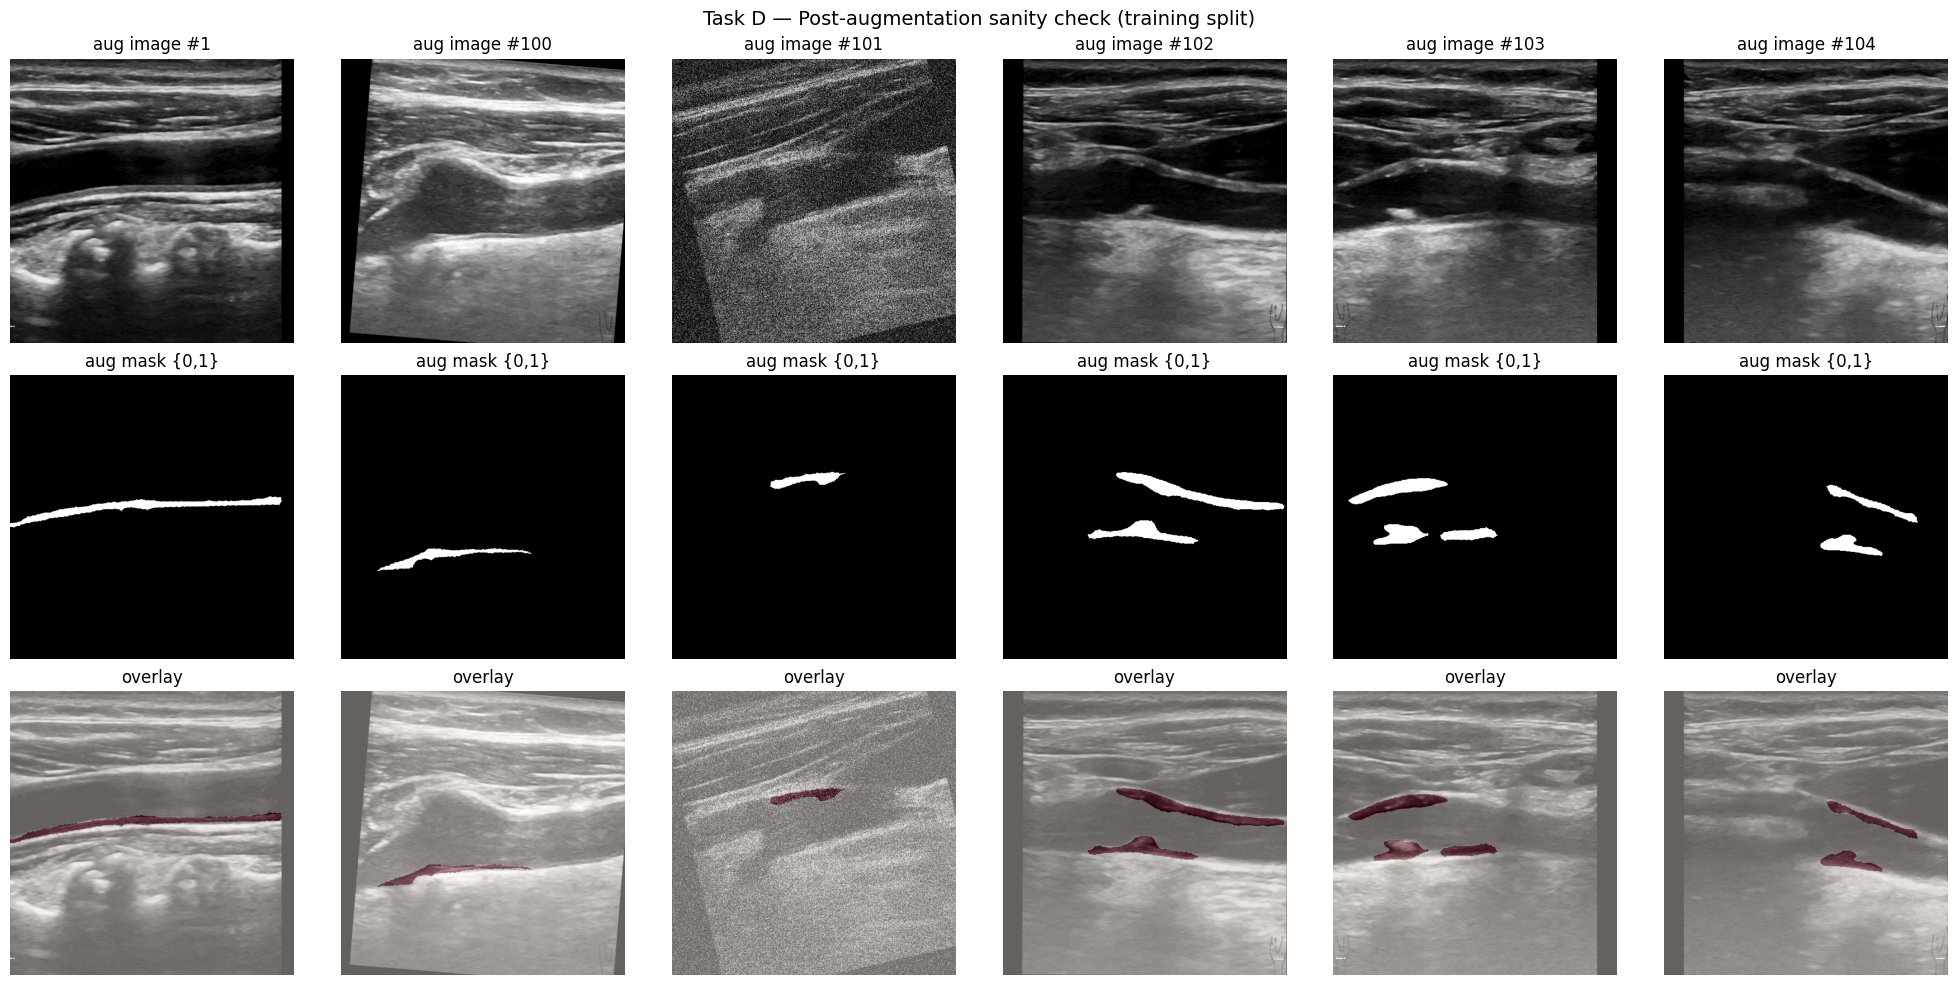

In [31]:
fig, axes = plt.subplots(3, 6, figsize=(20, 10))

plaque_pos_idx = train_df[train_df["has_plaque"] == 1].index[:6]

for col, ds_idx in enumerate(plaque_pos_idx):
    img_t, mask_t = train_ds[ds_idx]
    img_np = img_t.squeeze().numpy()
    mask_np = mask_t.numpy()

    axes[0, col].imshow(img_np, cmap="gray")
    axes[0, col].set_title(f"aug image #{train_df.iloc[ds_idx]['idx']}")
    axes[0, col].axis("off")

    axes[1, col].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title("aug mask {0,1}")
    axes[1, col].axis("off")

    axes[2, col].imshow(img_np, cmap="gray")
    axes[2, col].imshow(mask_np, cmap="Reds", alpha=0.4, vmin=0, vmax=1)
    axes[2, col].set_title("overlay")
    axes[2, col].axis("off")

plt.suptitle("Task D — Post-augmentation sanity check (training split)", fontsize=14)
plt.tight_layout()
plt.show()

The post-augmentation sanity-check grid confirms image-mask alignment is preserved through all geometric transforms (flip, rotation, resize), the binary class mapping remains clean ({0,1}, no intermediate values), and augmented plaque masks retain anatomically plausible shapes with no destroyed or empty regions. One sample showed strong Gaussian noise approaching the upper end of the configured variance range, which was judged acceptable as it remains representative of real-world ultrasound acquisition under suboptimal gain settings.